# 01 — Exploratory Data Analysis

## Genetic Variant Classification Using ClinVar

This notebook examines the processed ClinVar dataset used to classify genetic variants as benign or pathogenic.

The dataset contains 100,000 variants, evenly divided between two classes:

- **Benign (0):** Variants labeled Benign or Likely benign.
- **Pathogenic (1):** Variants labeled Pathogenic or Likely pathogenic.

The analysis begins with the dataset structure and class distribution, followed by an examination of mutation types, chromosomes, and genes. It also looks at allele lengths, missing values, and duplicate records to identify characteristics that may affect model performance.

The notebook uses the dataset generated by `src/preprocessing.py`. It does not modify the data or train any models.

## 1. Environment Setup

This notebook uses Pandas and NumPy to explore the data, with Matplotlib for plotting.

The analysis uses the processed ClinVar dataset stored in `data/processed/`.

In [6]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project root.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "clinvar_features.csv"

# Configure plot appearance.
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH}")

Project root: /Users/alexandrablaga/Documents/proiecte/genetic-variant-classification
Dataset path: /Users/alexandrablaga/Documents/proiecte/genetic-variant-classification/data/processed/clinvar_features.csv


## 2. Dataset Loading

The dataset contains ClinVar variants selected for the machine learning experiments.

During preprocessing, only variants mapped to GRCh38 and assigned one of the accepted clinical significance labels were kept. Duplicate records were removed based on their genomic identifiers.

The final dataset contains 100,000 variants, with 50,000 examples from each class.

In [29]:
# Load the processed ClinVar dataset.
df = pd.read_csv(DATA_PATH,low_memory=False)

print("Dataset loaded successfully.")
print(f"Number of variants: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully.
Number of variants: 100,000
Number of columns: 20


In [8]:
df.head()

,VariationID,Assembly,ClinicalSignificance,GeneSymbol,Chromosome,PositionVCF,OriginSimple,ReviewStatus,ReferenceAlleleVCF,AlternateAlleleVCF,target,ref,alt,ref_length,alt_length,length_difference,mutation_type,is_snv,is_deletion,is_insertion
0,1765428,GRCh38,Likely pathogenic,PALB2,16,23640991,germline,"criteria provided, multiple submitters, no con...",AGGAGGGGGTGGTCAGATGATACTGCTGCCCTCGGACTGCCGAGGA...,A,1,AGGAGGGGGTGGTCAGATGATACTGCTGCCCTCGGACTGCCGAGGA...,A,159,1,-158,Deletion,0,1,0
1,3601425,GRCh38,Pathogenic,MYO15A,17,18161447,germline,"criteria provided, single submitter",G,T,1,G,T,1,1,0,SNV,1,0,0
2,4809216,GRCh38,Likely benign,IFT122,3,129483480,germline,"criteria provided, single submitter",C,T,0,C,T,1,1,0,SNV,1,0,0
3,2676908,GRCh38,Likely pathogenic,NAGS,17,44007322,unknown,"criteria provided, single submitter",G,A,1,G,A,1,1,0,SNV,1,0,0
4,2861357,GRCh38,Likely pathogenic,IMPG2,3,101291478,germline,"criteria provided, single submitter",C,T,1,C,T,1,1,0,SNV,1,0,0


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   VariationID           100000 non-null  int64
 1   Assembly              100000 non-null  str  
 2   ClinicalSignificance  100000 non-null  str  
 3   GeneSymbol            100000 non-null  str  
 4   Chromosome            100000 non-null  str  
 5   PositionVCF           100000 non-null  int64
 6   OriginSimple          100000 non-null  str  
 7   ReviewStatus          100000 non-null  str  
 8   ReferenceAlleleVCF    100000 non-null  str  
 9   AlternateAlleleVCF    100000 non-null  str  
 10  target                100000 non-null  int64
 11  ref                   100000 non-null  str  
 12  alt                   100000 non-null  str  
 13  ref_length            100000 non-null  int64
 14  alt_length            100000 non-null  int64
 15  length_difference     100000 non-null  int64
 

## 3. Dataset Structure

The dataset includes original ClinVar fields and features derived during preprocessing.

The columns are grouped as follows:

**Genomic information**
- `Chromosome`
- `GeneSymbol`

**Variant information**
- `ReferenceAlleleVCF`
- `AlternateAlleleVCF`
- `OriginSimple`

**Derived features**
- `ref_length`
- `alt_length`
- `length_difference`
- `mutation_type`

**Target variable**
- `target`

The `target` column indicates whether a variant is classified as benign (0) or pathogenic (1).

In [10]:
column_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Unique Values": df.nunique(dropna=True).values
})

column_summary

,Column,Data Type,Missing Values,Unique Values
0,VariationID,int64,0,99998
1,Assembly,str,0,1
2,ClinicalSignificance,str,0,4
3,GeneSymbol,str,0,7534
4,Chromosome,str,0,25
5,PositionVCF,int64,0,98563
6,OriginSimple,str,0,5
7,ReviewStatus,str,0,5
8,ReferenceAlleleVCF,str,0,4341
9,AlternateAlleleVCF,str,0,2223


## 4. Target Class Distribution

The dataset contains 50,000 benign and 50,000 pathogenic variants, giving both classes equal representation.

This balance was introduced during preprocessing to make the initial model comparisons less affected by differences in class size.

The distribution is therefore specific to the sampled dataset and does not reflect the actual proportion of pathogenic variants in ClinVar or the general population.

In [30]:
class_counts = (df["target"].value_counts().sort_index())

class_distribution = pd.DataFrame({
    "Class": ["Benign", "Pathogenic"],
    "Count": [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ]
})

class_distribution["Percentage"] = (class_distribution["Count"] / len(df) * 100)

class_distribution

,Class,Count,Percentage
0,Benign,50000,50.0
1,Pathogenic,50000,50.0


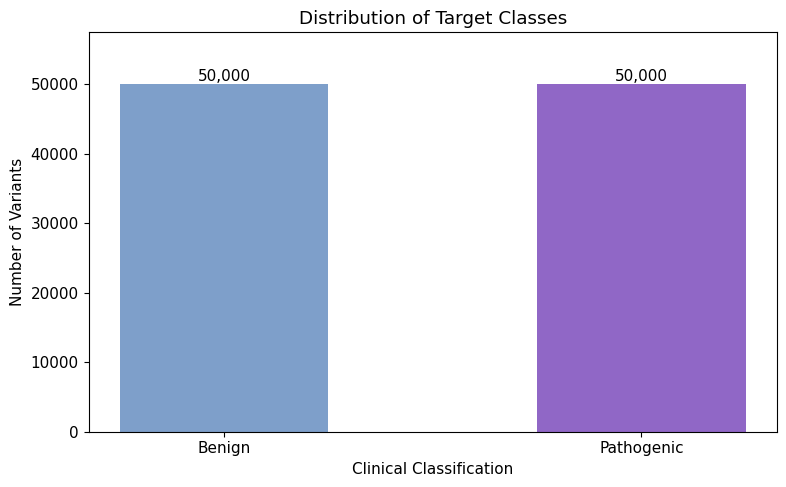

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    class_distribution["Class"],
    class_distribution["Count"],
    color=["#7E9FCA", "#9067C6"],
    width=0.5
)

ax.set_title("Distribution of Target Classes")
ax.set_xlabel("Clinical Classification")
ax.set_ylabel("Number of Variants")

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 500,
        f"{int(height):,}",
        ha="center"
    )

ax.set_ylim(0, class_distribution["Count"].max() * 1.15)

plt.tight_layout()
plt.show()

### Interpretation

The equal number of benign and pathogenic variants reflects the sampling method used during preprocessing, not the original distribution in ClinVar.

This allows the models to be compared using the same class proportions. However, the results must be interpreted with this balance in mind, particularly when considering evaluation metrics and predicted probabilities.

## 5. Mutation Type Analysis

Variants are grouped into four categories based on their reference and alternate alleles:

- **SNV:** A change involving a single nucleotide.
- **Insertion:** The alternate allele is longer than the reference allele.
- **Deletion:** The reference allele is longer than the alternate allele.
- **Other:** Variants that do not fit the categories above.

This section examines how frequently each mutation type occurs and how its distribution differs between benign and pathogenic variants.

In [31]:
mutation_counts = (df["mutation_type"].value_counts())

mutation_counts

mutation_type
SNV          73904
Deletion     17620
Insertion     8118
Other          358
Name: count, dtype: int64

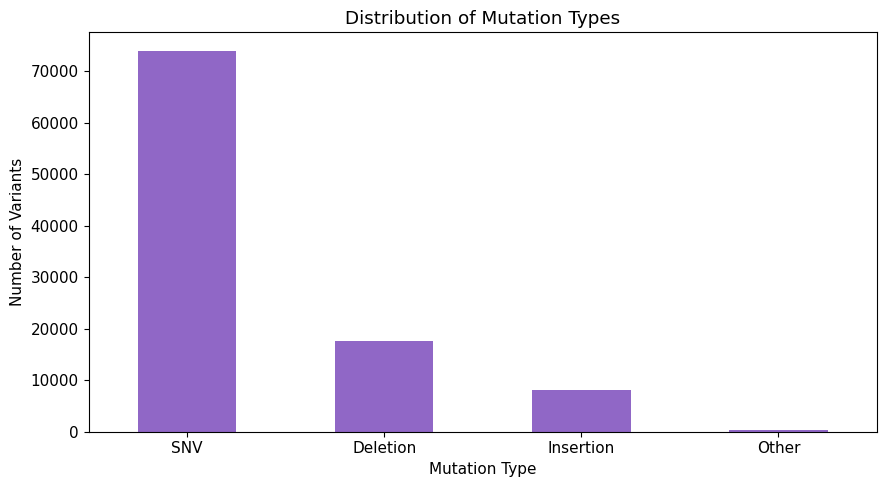

In [32]:
fig, ax = plt.subplots(figsize=(9, 5))

mutation_counts.plot(kind="bar",ax=ax,color="#9067C6")

ax.set_title("Distribution of Mutation Types")
ax.set_xlabel("Mutation Type")
ax.set_ylabel("Number of Variants")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
mutation_by_class = pd.crosstab(df["mutation_type"],df["target"])

mutation_by_class = mutation_by_class.rename(
    columns={
        0: "Benign",
        1: "Pathogenic"
    }
)

mutation_by_class

target,Benign,Pathogenic
mutation_type,,
Deletion,1529,16091
Insertion,1017,7101
Other,100,258
SNV,47354,26550


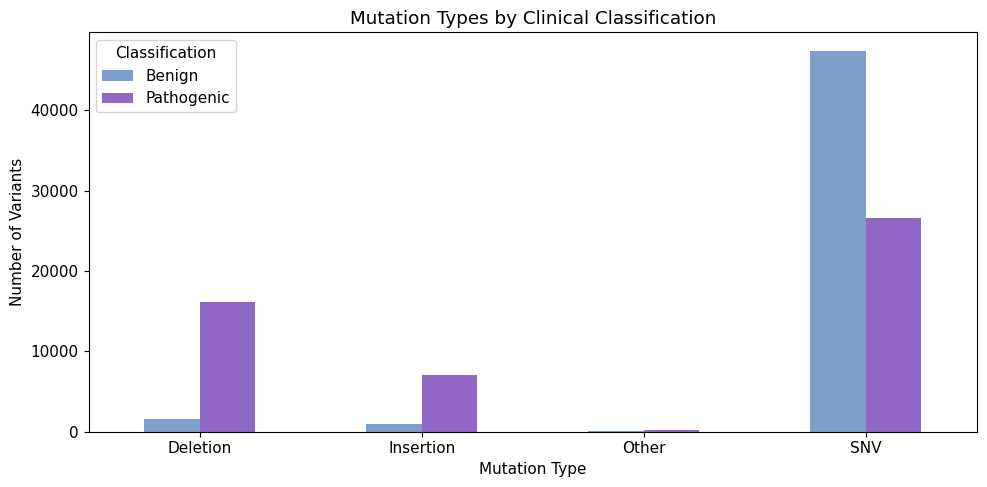

In [34]:
mutation_by_class.plot(kind="bar",figsize=(10, 5),color=["#7E9FCA", "#9067C6"])

plt.title("Mutation Types by Clinical Classification")
plt.xlabel("Mutation Type")
plt.ylabel("Number of Variants")
plt.xticks(rotation=0)
plt.legend(title="Classification")

plt.tight_layout()
plt.show()

### Interpretation

Mutation types may occur at different frequencies in benign and pathogenic variants, making them potentially useful for classification.

However, mutation type alone is not enough to determine pathogenicity. Its predictive value depends on other features, including genomic context.

The categories used in this dataset are based on allele lengths and provide only a simplified description of each variant.

## 6. Chromosome Distribution

The `Chromosome` feature indicates which chromosome contains each variant.

This section examines how variants are distributed across chromosomes. Differences in their frequencies may be influenced by ClinVar submission patterns, the genes represented in the database, and the selection criteria used during preprocessing.

In [17]:
chromosome_counts = df["Chromosome"].value_counts()

chromosome_counts

Chromosome
2     10158
1      8103
17     6845
11     5812
X      5615
3      5271
16     5141
5      4794
7      4587
19     4494
6      4438
9      4312
12     4304
15     3656
10     3443
8      3347
4      3126
14     2958
13     2634
22     2115
20     1935
18     1639
21     1154
MT       79
Y        40
Name: count, dtype: int64

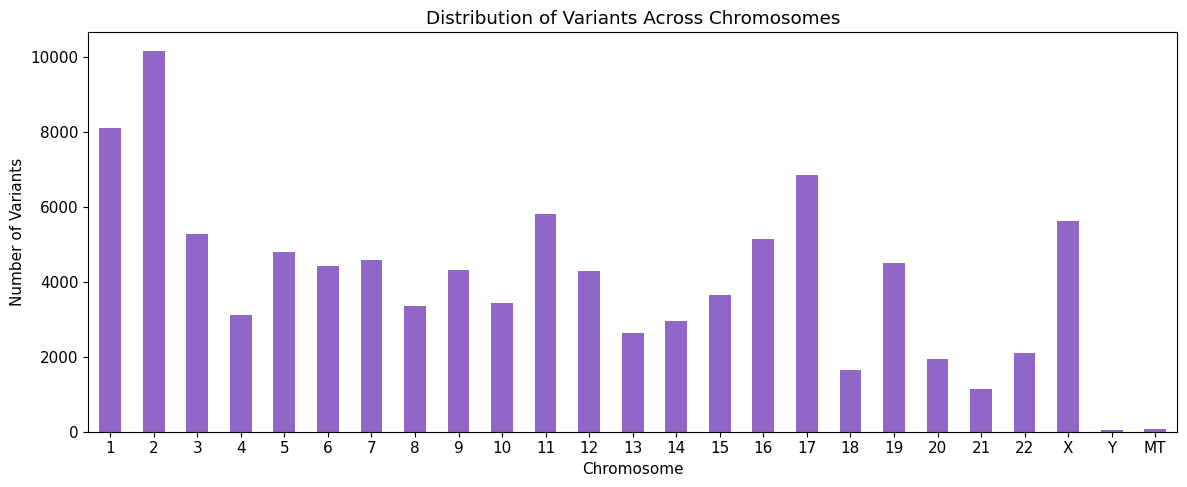

In [35]:
chromosome_order = ([str(i) for i in range(1, 23)]+ ["X", "Y", "MT"])

chromosome_counts = (df["Chromosome"].astype(str).value_counts().reindex(chromosome_order, fill_value=0))

fig, ax = plt.subplots(figsize=(12, 5))

chromosome_counts.plot(kind="bar",ax=ax,color="#9067C6")

ax.set_title("Distribution of Variants Across Chromosomes")
ax.set_xlabel("Chromosome")
ax.set_ylabel("Number of Variants")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

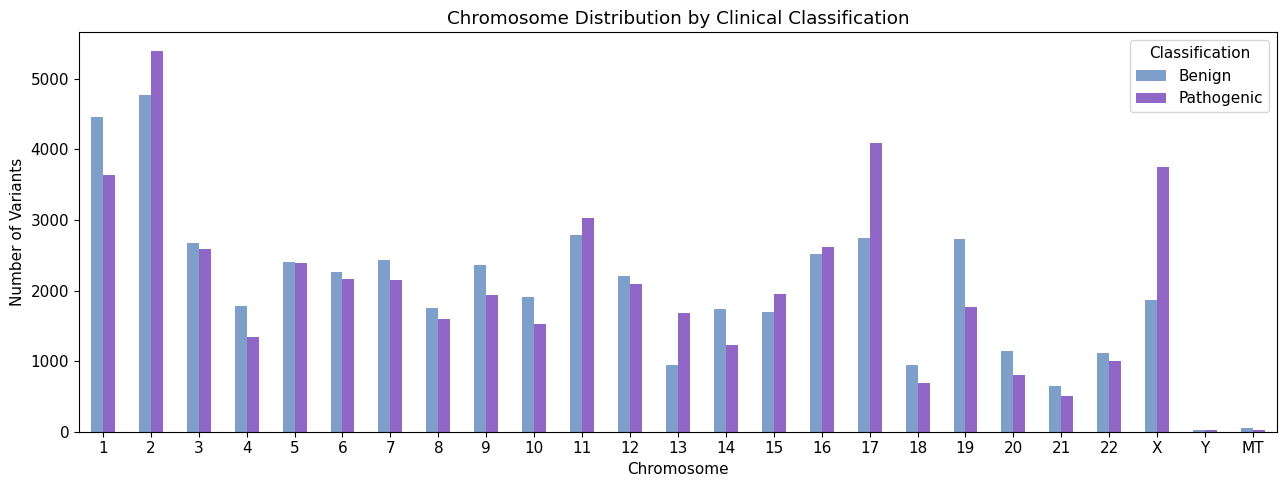

In [36]:
chromosome_by_class = pd.crosstab(df["Chromosome"].astype(str),df["target"])

chromosome_by_class = chromosome_by_class.reindex(chromosome_order,fill_value=0)

chromosome_by_class = chromosome_by_class.rename(
    columns={
        0: "Benign",
        1: "Pathogenic"
    }
)

chromosome_by_class.plot(kind="bar",figsize=(13, 5),color=["#7E9FCA", "#9067C6"])

plt.title("Chromosome Distribution by Clinical Classification")
plt.xlabel("Chromosome")
plt.ylabel("Number of Variants")

plt.xticks(rotation=0)
plt.legend(title="Classification")

plt.tight_layout()
plt.show()

### Interpretation

Variant counts differ across chromosomes, but this does not mean that variants on certain chromosomes are more likely to be pathogenic.

The differences may reflect gene coverage, clinical testing practices, and ClinVar submission patterns rather than biological differences in pathogenicity.

These distributions describe the selected dataset and provide context for the machine learning analysis.

## 7. Gene Distribution

The `GeneSymbol` feature identifies the gene associated with each variant.

Some genes may appear more frequently than others in ClinVar, depending on how extensively they have been studied and submitted to the database.

This section counts the genes represented in the dataset and identifies those with the highest number of variants.

In [20]:
unique_genes = df["GeneSymbol"].nunique()

print(f"Number of unique gene symbols: {unique_genes:,}")

Number of unique gene symbols: 7,534


In [37]:
top_genes = (df["GeneSymbol"].value_counts().head(15))

top_genes

GeneSymbol
TTN      1500
BRCA2    1047
NF1      1006
BRCA1     797
ATM       698
FBN1      580
NEB       491
APC       484
DMD       457
USH2A     437
MSH6      381
MSH2      381
PKD1      373
SCN1A     355
PKHD1     336
Name: count, dtype: int64

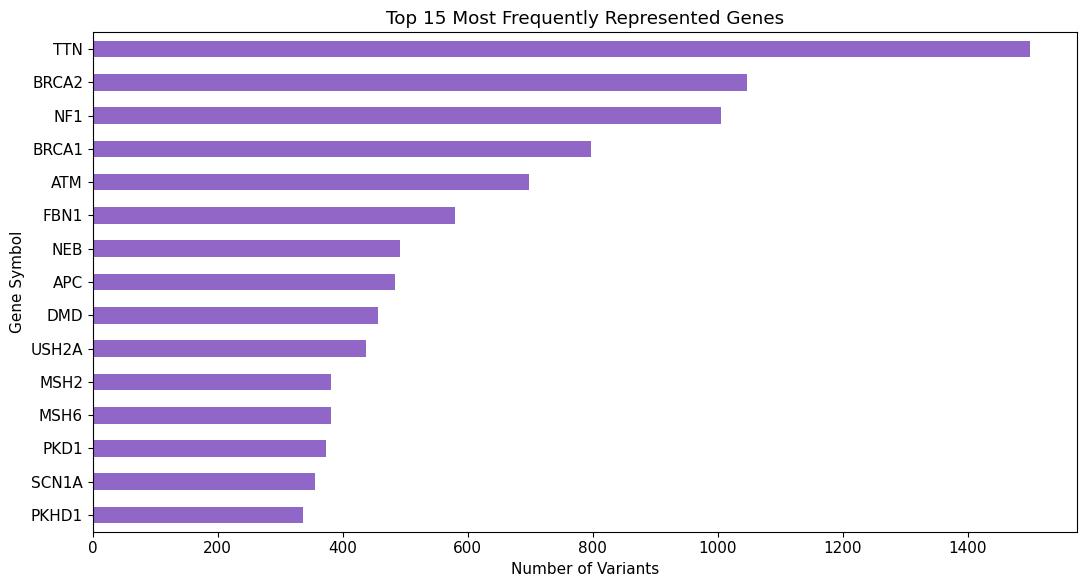

In [38]:
fig, ax = plt.subplots(figsize=(11, 6))

top_genes.sort_values().plot(kind="barh",ax=ax,color="#9067C6")

ax.set_title("Top 15 Most Frequently Represented Genes")
ax.set_xlabel("Number of Variants")
ax.set_ylabel("Gene Symbol")

plt.tight_layout()
plt.show()

### Interpretation

Gene representation varies across the dataset, with some genes appearing more frequently than others. This may affect model performance when `GeneSymbol` is included as a predictor.

With a random train-test split, variants from the same gene can appear in both sets. The model may therefore perform well on genes it has already encountered during training.

To examine this effect, the project also evaluates model performance using gene-based splits, where the genes in the test set are excluded from training.

## 8. Allele Length Analysis

The dataset includes three numerical features describing the lengths of reference and alternate alleles:

- **`ref_length`:** Number of nucleotides in the reference allele.
- **`alt_length`:** Number of nucleotides in the alternate allele.
- **`length_difference`:** Difference between the alternate and reference allele lengths.

These features describe basic aspects of variant structure. This section examines their distributions, including common values and unusually large differences in allele length.

In [39]:
structural_features = [ "ref_length","alt_length","length_difference"]

df[structural_features].describe()

,ref_length,alt_length,length_difference
count,100000.00000,100000.000000,100000.000000
mean,10.38221,2.174660,-8.207550
std,216.81383,58.696664,222.968044
min,1.00000,1.000000,-9912.000000
25%,1.00000,1.000000,0.000000
50%,1.00000,1.000000,0.000000
75%,1.00000,1.000000,0.000000
max,9913.00000,8119.000000,8118.000000


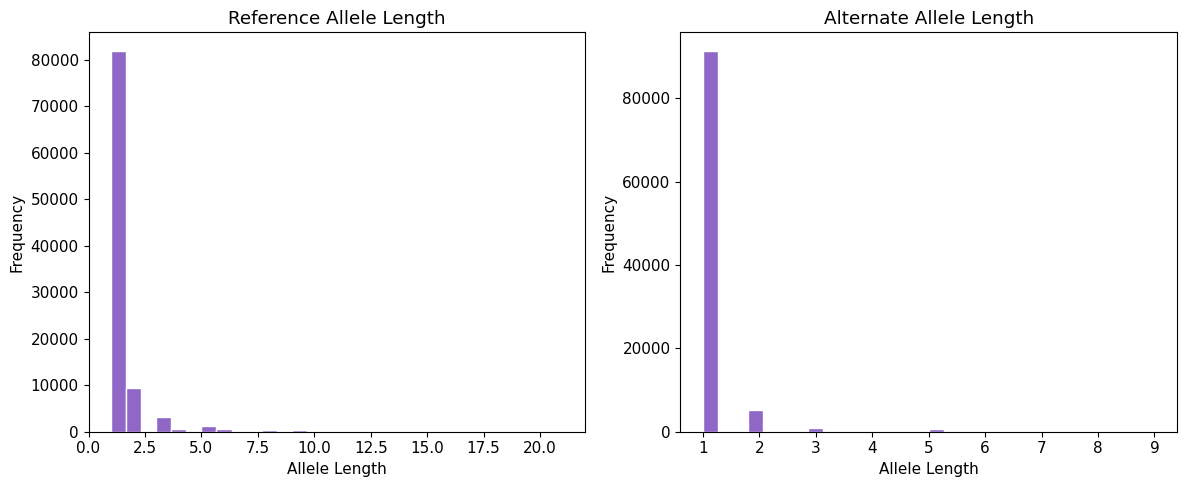

In [40]:
fig, axes = plt.subplots(1,2,figsize=(12, 5))

for ax, column, title in zip(
    axes,
    ["ref_length", "alt_length"],
    ["Reference Allele Length", "Alternate Allele Length"]
):
    upper_limit = df[column].quantile(0.99)

    values = df.loc[
        df[column] <= upper_limit,
        column
    ]

    ax.hist(values,bins=30,color="#9067C6",edgecolor="white")

    ax.set_title(title)
    ax.set_xlabel("Allele Length")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

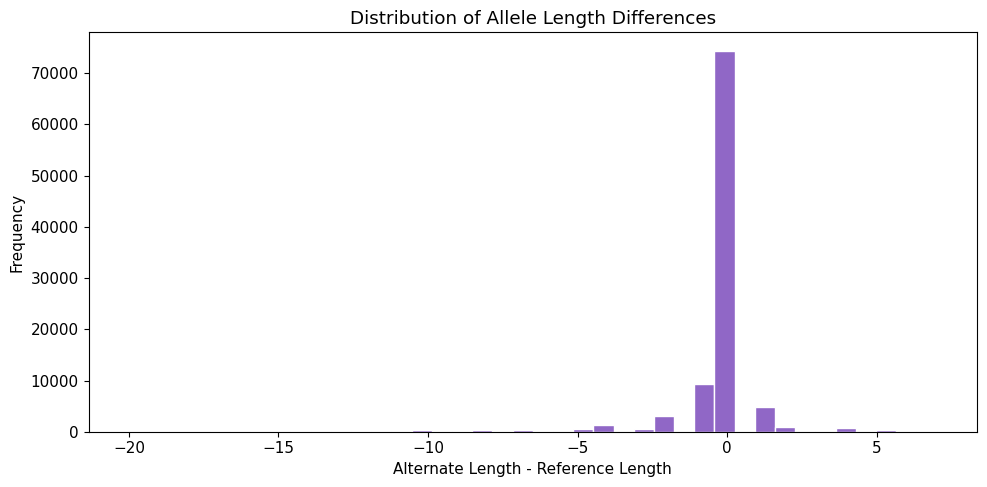

In [41]:
length_difference = df["length_difference"]

lower_limit = length_difference.quantile(0.01)
upper_limit = length_difference.quantile(0.99)

filtered_difference = length_difference[
    length_difference.between(lower_limit,upper_limit)
]

plt.figure(figsize=(10, 5))

plt.hist(filtered_difference,bins=40,color="#9067C6",edgecolor="white")

plt.title("Distribution of Allele Length Differences")
plt.xlabel("Alternate Length - Reference Length")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Interpretation

Allele lengths help distinguish between different types of genetic variants. Single-nucleotide substitutions have reference and alternate alleles of equal length, while insertions and deletions produce differences in length.

Most variants are expected to have relatively short alleles, although longer sequences may also occur. Extreme values are kept in the dataset but omitted from some plots to make the distributions easier to read.

Because `mutation_type` is also derived from allele lengths, these features contain overlapping information.

## 9. Data Quality Assessment

This section checks the processed dataset for missing values, duplicate records, and consistency in the target labels.

The checks cover:

- Missing values in each column.
- Exact duplicate rows.
- Variants with duplicate genomic identifiers.
- Values and class counts in the `target` column.

Filtering and deduplication were performed during preprocessing. These checks help verify the resulting dataset before it is used for model training.

In [42]:
missing_values = (df.isna().sum().sort_values(ascending=False))

missing_values = missing_values[missing_values > 0]

if missing_values.empty:
    print("No missing values found.")
else:
    display(missing_values.to_frame(name="Missing Values"))

No missing values found.


In [43]:
duplicate_rows = df.duplicated().sum()

print(f"Exact duplicate rows: {duplicate_rows:,}")

variant_identifier = [
    "Chromosome",
    "PositionVCF",
    "ReferenceAlleleVCF",
    "AlternateAlleleVCF"
]

if all(column in df.columns for column in variant_identifier):

    duplicate_variants = df.duplicated(subset=variant_identifier).sum()

    print(f"Duplicate genomic variants: {duplicate_variants:,}")
else:
    print( "Genomic identifier columns are not all available.")

Exact duplicate rows: 0
Duplicate genomic variants: 0


In [44]:
if all(column in df.columns for column in variant_identifier):

    conflicting_labels = (df.groupby(variant_identifier)["target"].nunique())

    conflicting_labels = (conflicting_labels > 1).sum()

    print(
        f"Variants with conflicting target labels: "
        f"{conflicting_labels:,}"
    )

Variants with conflicting target labels: 0


### Interpretation

The preprocessing pipeline removes duplicate genomic identifiers and records with conflicting classifications. The checks above help verify that these steps produced the expected results.

Missing values do not necessarily indicate invalid records, as some ClinVar metadata fields may be incomplete.

Even when no exact duplicates are found, biologically equivalent variants may still appear under different representations if they have not been fully normalized.

## 10. Summary and Key Observations

This notebook explored the 100,000 ClinVar variants selected for the classification experiments.

The dataset contains equal numbers of benign and pathogenic variants. Mutation types, chromosome locations, and gene frequencies were examined to better understand its composition. The analysis also covered reference and alternate allele lengths, missing values, and duplicate records.

Gene representation varies across the dataset, which may affect how models perform when evaluated on previously unseen genes. The structural features describe basic differences between alleles but do not capture the full biological context of each variant.

### Limitations

The dataset reflects ClinVar's submission and annotation practices. Its balanced class distribution was introduced during preprocessing and does not represent the prevalence of pathogenic variants in ClinVar or the general population.

The available features are also limited to genomic information and basic variant characteristics. They cannot fully describe the biological mechanisms involved in pathogenicity.

### Next Steps

The next notebook, `02_model_evaluation.ipynb`, compares three classification models: Dummy Classifier, Logistic Regression, and Random Forest.

Their performance is examined using classification metrics, confusion matrices, ROC curves, and precision–recall curves.